<a href="https://colab.research.google.com/github/aswanth14-pixel/Machine-Learning/blob/main/Patient_Disease_Progression_HMM.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Hidden Markov Model for Patient Disease Progression
**Part B | Google Colab**

This notebook demonstrates an HMM with four hidden states:
0. Stable
1. Sub-clinical
2. Acute
3. Critical

It includes:
- Loading timestamped patient vital-sign data
- Sorting observations into patient sequences
- Standardizing continuous measurements
- A Gaussian HMM implemented with NumPy
- Scaled Forward and Backward algorithms to reduce numerical underflow
- Baum-Welch maximum-likelihood parameter estimation
- Viterbi decoding
- Plots and a short results summary

**Dataset requirement:** Use a time-series CSV with repeated measurements per patient, plus a patient identifier, timestamp, and physiological features. The Part A dataset may not have repeated timestamped observations, so it is not appropriate for this notebook.

**Suggested starting dataset:** [Synthetic Health Monitoring Dataset on GitHub](https://github.com/shrish842/Synthetic-Health-Monitoring-Dataset), whose repository describes patient IDs, timestamps, heart rate, blood pressure and SpO₂. If you already downloaded a different Kaggle time-series CSV, you can upload that instead.

> Educational demonstration only. Hidden states are statistical patterns, not medical diagnoses. The Stable/Sub-clinical/Acute/Critical names are assigned after fitting by ranking a simple vital-sign severity score; this is not clinically validated.

## Step 1: Import libraries

In [1]:
import io
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from google.colab import files
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
np.random.seed(42)

print("Libraries imported successfully.")

Libraries imported successfully.


## Step 2: Upload the time-series CSV

In [3]:
uploaded = files.upload()
csv_files = [name for name in uploaded if name.lower().endswith(".csv")]
if not csv_files:
    raise ValueError("Please upload a time-series CSV file.")
file_name = csv_files[0]
df = pd.read_csv(io.BytesIO(uploaded[file_name]))

print("Loaded:", file_name)
print("Shape:", df.shape)
print("Columns:", df.columns.tolist())
display(df.head())
display(pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "missing": df.isna().sum()
}))

Saving synthetic_health_dataset_stratified_20_patients.csv to synthetic_health_dataset_stratified_20_patients.csv
Loaded: synthetic_health_dataset_stratified_20_patients.csv
Shape: (1051200, 22)
Columns: ['Patient_ID', 'Timestamp', 'Age', 'Gender', 'Weight', 'Height', 'BMI', 'Heart_Rate', 'BP_Systolic', 'BP_Diastolic', 'SpO2', 'Respiration_Rate', 'Body_Temperature', 'Blood_Glucose', 'Activity_Level', 'Sleep_Pattern', 'Risk_Profile', 'Hypertension_Label', 'Anomaly_Type', 'Is_Anomaly', 'Data_Quality_Flag', 'Missing_Mechanism']


,Patient_ID,Timestamp,Age,Gender,Weight,Height,BMI,Heart_Rate,BP_Systolic,BP_Diastolic,...,Body_Temperature,Blood_Glucose,Activity_Level,Sleep_Pattern,Risk_Profile,Hypertension_Label,Anomaly_Type,Is_Anomaly,Data_Quality_Flag,Missing_Mechanism
0,1,2025-01-01 00:00:00,44,Female,63.428666,160.852174,24.514989,64.983253,119.316229,74.359810,...,98.873764,98.147098,3.0,2,moderate_risk,0,none,0,valid,none
1,1,2025-01-01 00:10:00,44,Female,63.440376,160.852174,24.519515,67.370818,120.036205,74.738841,...,98.900441,101.213780,6.0,0,moderate_risk,0,none,0,valid,none
2,1,2025-01-01 00:20:00,44,Female,63.436596,160.852174,24.518054,65.942703,121.965136,75.406949,...,98.892635,102.199192,1.0,2,moderate_risk,0,none,0,valid,none
3,1,2025-01-01 00:30:00,44,Female,63.420567,160.852174,24.511859,65.742632,122.971756,75.722588,...,98.903550,100.494127,1.0,2,moderate_risk,0,none,0,valid,none
4,1,2025-01-01 00:40:00,44,Female,63.404973,160.852174,24.505832,66.055647,122.800885,75.843408,...,98.935292,100.111263,1.0,1,moderate_risk,0,none,0,valid,none


,dtype,missing
Patient_ID,int64,0
Timestamp,object,0
Age,int64,0
Gender,object,0
Weight,float64,0
Height,float64,0
BMI,float64,0
Heart_Rate,float64,54133
BP_Systolic,float64,0
BP_Diastolic,float64,0


## Step 3: Detect patient ID, timestamp and vital-sign columns
This cell tries common column names. **Review the detected columns.** If any are wrong, edit the three variables in the next cell using exact column names from your CSV.

In [4]:
def find_column(columns, candidates):
    normalized = {str(c).strip().lower().replace(" ", "_"): c for c in columns}
    for candidate in candidates:
        key = candidate.lower().replace(" ", "_")
        if key in normalized:
            return normalized[key]
    # partial match fallback
    for c in columns:
        key = str(c).strip().lower().replace(" ", "_")
        if any(candidate.lower().replace(" ", "_") in key for candidate in candidates):
            return c
    return None

patient_col = find_column(df.columns, [
    "patient_id", "patientid", "patient_number", "subject_id", "person_id", "user_id"
])
time_col = find_column(df.columns, [
    "timestamp", "datetime", "date_time", "measurement_time", "recorded_at", "time"
])

feature_candidates = {
    "heart_rate": ["heart_rate", "heartrate", "heart_rate_bpm", "pulse_rate", "pulse"],
    "systolic_bp": ["systolic_bp", "bp_systolic", "systolic_blood_pressure", "sbp"],
    "diastolic_bp": ["diastolic_bp", "bp_diastolic", "diastolic_blood_pressure", "dbp"],
    "oxygen_saturation": ["spo2", "oxygen_saturation", "blood_oxygen", "oxygen_saturation_percent"],
    "respiratory_rate": ["respiratory_rate", "respiration_rate", "breathing_rate"],
    "temperature": ["body_temperature", "temperature", "temp_c"]
}
feature_columns = []
for concept, candidates in feature_candidates.items():
    col = find_column(df.columns, candidates)
    if col is not None and col not in feature_columns:
        feature_columns.append(col)

print("Detected patient ID column:", patient_col)
print("Detected timestamp column:", time_col)
print("Detected vital-sign columns:", feature_columns)
print("\nAll columns:", df.columns.tolist())

# If detection is incorrect, manually edit these variables:
# patient_col = "patient_id"
# time_col = "timestamp"
# feature_columns = ["heart_rate", "systolic_bp", "diastolic_bp", "spo2"]

if patient_col is None or time_col is None:
    raise ValueError(
        "A patient ID and timestamp column are required. Set patient_col and time_col manually. "
        "The CSV must contain repeated observations over time for each patient."
    )
if len(feature_columns) < 2:
    raise ValueError(
        "Could not detect at least two vital-sign columns. Edit feature_columns manually "
        "using numeric physiological measurement columns."
    )

Detected patient ID column: Patient_ID
Detected timestamp column: Timestamp
Detected vital-sign columns: ['Heart_Rate', 'BP_Systolic', 'BP_Diastolic', 'SpO2', 'Respiration_Rate', 'Body_Temperature']

All columns: ['Patient_ID', 'Timestamp', 'Age', 'Gender', 'Weight', 'Height', 'BMI', 'Heart_Rate', 'BP_Systolic', 'BP_Diastolic', 'SpO2', 'Respiration_Rate', 'Body_Temperature', 'Blood_Glucose', 'Activity_Level', 'Sleep_Pattern', 'Risk_Profile', 'Hypertension_Label', 'Anomaly_Type', 'Is_Anomaly', 'Data_Quality_Flag', 'Missing_Mechanism']


## Step 4: Clean data and build patient sequences

In [5]:
data = df.copy()
data[time_col] = pd.to_datetime(data[time_col], errors="coerce")
data = data.dropna(subset=[patient_col, time_col]).copy()

for col in feature_columns:
    data[col] = pd.to_numeric(data[col], errors="coerce")

# Drop features that contain no usable numeric values.
feature_columns = [c for c in feature_columns if data[c].notna().any()]
if len(feature_columns) < 2:
    raise ValueError("At least two selected vital-sign columns must contain numeric values.")

data = data.sort_values([patient_col, time_col]).reset_index(drop=True)

# Keep patients with at least 4 measurements, so short sequences do not dominate.
sequence_lengths = data.groupby(patient_col).size()
valid_patients = sequence_lengths[sequence_lengths >= 4].index
data = data[data[patient_col].isin(valid_patients)].copy()

if data.empty:
    raise ValueError("No patient has at least 4 timestamped observations. Check your dataset and column selections.")

imputer = SimpleImputer(strategy="median")
data[feature_columns] = imputer.fit_transform(data[feature_columns])

scaler = StandardScaler()
data[[f"{c}_scaled" for c in feature_columns]] = scaler.fit_transform(data[feature_columns])

scaled_columns = [f"{c}_scaled" for c in feature_columns]
sequences = []
sequence_patient_ids = []
for pid, group in data.groupby(patient_col, sort=False):
    arr = group[scaled_columns].to_numpy(dtype=float)
    if len(arr) >= 4 and np.isfinite(arr).all():
        sequences.append(arr)
        sequence_patient_ids.append(pid)

if not sequences:
    raise ValueError("No valid sequences were created. Check missing values and selected columns.")

X_all = np.vstack(sequences)
print("Patients/sequences used:", len(sequences))
print("Observations used:", len(X_all))
print("Vital-sign features:", feature_columns)
print("Sequence length summary:")
display(pd.Series([len(s) for s in sequences], name="observations_per_patient").describe().to_frame())

Patients/sequences used: 20
Observations used: 1051200
Vital-sign features: ['Heart_Rate', 'BP_Systolic', 'BP_Diastolic', 'SpO2', 'Respiration_Rate', 'Body_Temperature']
Sequence length summary:


,observations_per_patient
count,20.0
mean,52560.0
std,0.0
min,52560.0
25%,52560.0
50%,52560.0
75%,52560.0
max,52560.0


## Step 5: Define the Gaussian HMM
Each hidden state has a multivariate Gaussian emission distribution. For a manageable assignment implementation, we use diagonal covariance matrices, which assume that feature noise is independent within each state.

We will estimate:
- Initial state probabilities (`pi`)
- State transition probabilities (`A`)
- State-specific Gaussian means and variances

In [6]:
class GaussianHMM:
    def __init__(self, n_states=4, n_iter=30, tol=1e-3, var_floor=1e-3, random_state=42):
        self.n_states = n_states
        self.n_iter = n_iter
        self.tol = tol
        self.var_floor = var_floor
        self.random_state = random_state
        self.log_likelihood_history = []

    def _logsumexp(self, a, axis=None):
        m = np.max(a, axis=axis, keepdims=True)
        out = m + np.log(np.sum(np.exp(a - m), axis=axis, keepdims=True) + 1e-300)
        if axis is not None:
            out = np.squeeze(out, axis=axis)
        return out

    def _log_emission(self, X):
        # Returns log p(x_t | state k), shape (T, K)
        T, D = X.shape
        result = np.empty((T, self.n_states))
        for k in range(self.n_states):
            var = np.maximum(self.variances[k], self.var_floor)
            log_const = -0.5 * np.sum(np.log(2 * np.pi * var))
            diff = X - self.means[k]
            result[:, k] = log_const - 0.5 * np.sum((diff ** 2) / var, axis=1)
        return result

    def _forward_scaled(self, logB):
        # Scaling factors c[t] keep forward values numerically stable.
        T, K = logB.shape
        B = np.exp(logB - np.max(logB, axis=1, keepdims=True))
        # Per-time emission rescaling is tracked in log likelihood separately.
        alpha = np.zeros((T, K))
        scales = np.zeros(T)

        alpha[0] = self.pi * B[0]
        scales[0] = max(alpha[0].sum(), 1e-300)
        alpha[0] /= scales[0]

        for t in range(1, T):
            alpha[t] = (alpha[t-1] @ self.A) * B[t]
            scales[t] = max(alpha[t].sum(), 1e-300)
            alpha[t] /= scales[t]

        # Restore the per-row emission offsets to the log likelihood.
        row_offsets = np.max(logB, axis=1)
        log_likelihood = np.sum(np.log(scales) + row_offsets)
        return alpha, scales, B, log_likelihood

    def _backward_scaled(self, B, scales):
        T, K = B.shape
        beta = np.zeros((T, K))
        beta[-1] = 1.0
        for t in range(T - 2, -1, -1):
            beta[t] = self.A @ (B[t+1] * beta[t+1])
            beta[t] /= max(scales[t+1], 1e-300)
        return beta

    def _initialize(self, sequences):
        rng = np.random.default_rng(self.random_state)
        X = np.vstack(sequences)
        T, D = X.shape
        # Initialize means from random observations; variances from global variance.
        chosen = rng.choice(T, size=self.n_states, replace=(T < self.n_states))
        self.means = X[chosen].copy()
        global_var = np.var(X, axis=0) + self.var_floor
        self.variances = np.tile(global_var, (self.n_states, 1))
        self.pi = np.full(self.n_states, 1.0 / self.n_states)
        self.A = np.full((self.n_states, self.n_states), 0.05 / max(self.n_states - 1, 1))
        np.fill_diagonal(self.A, 0.95)
        self.A /= self.A.sum(axis=1, keepdims=True)

    def fit(self, sequences):
        self._initialize(sequences)
        previous_ll = -np.inf

        for iteration in range(self.n_iter):
            pi_sum = np.zeros(self.n_states)
            trans_sum = np.zeros((self.n_states, self.n_states))
            gamma_sum = np.zeros(self.n_states)
            mean_num = np.zeros_like(self.means)
            second_num = np.zeros_like(self.means)
            total_ll = 0.0

            for X in sequences:
                logB = self._log_emission(X)
                alpha, scales, B, ll = self._forward_scaled(logB)
                beta = self._backward_scaled(B, scales)
                total_ll += ll

                gamma = alpha * beta
                gamma /= np.maximum(gamma.sum(axis=1, keepdims=True), 1e-300)

                # Xi[t, i, j] is the posterior probability of transition i -> j.
                xi_sum = np.zeros((self.n_states, self.n_states))
                for t in range(len(X) - 1):
                    xi = alpha[t, :, None] * self.A * (B[t+1] * beta[t+1])[None, :]
                    denom = xi.sum()
                    if denom > 0:
                        xi_sum += xi / denom

                pi_sum += gamma[0]
                trans_sum += xi_sum
                gamma_sum += gamma.sum(axis=0)
                mean_num += gamma.T @ X
                second_num += gamma.T @ (X ** 2)

            self.pi = pi_sum / max(pi_sum.sum(), 1e-300)
            self.A = trans_sum + 1e-6
            self.A /= self.A.sum(axis=1, keepdims=True)

            self.means = mean_num / np.maximum(gamma_sum[:, None], 1e-300)
            second_moment = second_num / np.maximum(gamma_sum[:, None], 1e-300)
            self.variances = np.maximum(second_moment - self.means ** 2, self.var_floor)

            self.log_likelihood_history.append(total_ll)
            print(f"Iteration {iteration+1:02d}: log-likelihood = {total_ll:.2f}")

            if iteration > 0 and abs(total_ll - previous_ll) < self.tol:
                print("Converged based on log-likelihood change.")
                break
            previous_ll = total_ll
        return self

    def score(self, X):
        _, _, _, ll = self._forward_scaled(self._log_emission(X))
        return ll

    def predict(self, X):
        # Viterbi decoding in log space.
        logB = self._log_emission(X)
        T, K = logB.shape
        logA = np.log(np.maximum(self.A, 1e-300))
        logpi = np.log(np.maximum(self.pi, 1e-300))
        delta = np.zeros((T, K))
        psi = np.zeros((T, K), dtype=int)
        delta[0] = logpi + logB[0]

        for t in range(1, T):
            candidates = delta[t-1][:, None] + logA
            psi[t] = np.argmax(candidates, axis=0)
            delta[t] = np.max(candidates, axis=0) + logB[t]

        states = np.zeros(T, dtype=int)
        states[-1] = np.argmax(delta[-1])
        for t in range(T-2, -1, -1):
            states[t] = psi[t+1, states[t+1]]
        return states

print("GaussianHMM class defined.")

GaussianHMM class defined.


## Step 6: Fit the HMM using Baum-Welch
Baum-Welch is an Expectation-Maximization (EM) algorithm. The E-step estimates the posterior probabilities of hidden states/transitions with Forward-Backward; the M-step updates initial, transition, and Gaussian emission parameters.

Iteration 01: log-likelihood = -8153827.70
Iteration 02: log-likelihood = -5252407.12
Iteration 03: log-likelihood = -4558076.28
Iteration 04: log-likelihood = -4520291.07
Iteration 05: log-likelihood = -4511143.61
Iteration 06: log-likelihood = -4506487.20
Iteration 07: log-likelihood = -4503691.90
Iteration 08: log-likelihood = -4501772.87
Iteration 09: log-likelihood = -4500349.78
Iteration 10: log-likelihood = -4499289.44
Iteration 11: log-likelihood = -4498557.45
Iteration 12: log-likelihood = -4498114.73
Iteration 13: log-likelihood = -4497838.84
Iteration 14: log-likelihood = -4497670.22
Iteration 15: log-likelihood = -4497569.90
Iteration 16: log-likelihood = -4497509.19
Iteration 17: log-likelihood = -4497472.29
Iteration 18: log-likelihood = -4497450.35
Iteration 19: log-likelihood = -4497437.59
Iteration 20: log-likelihood = -4497430.31
Iteration 21: log-likelihood = -4497426.19
Iteration 22: log-likelihood = -4497423.87
Iteration 23: log-likelihood = -4497422.56
Iteration 2

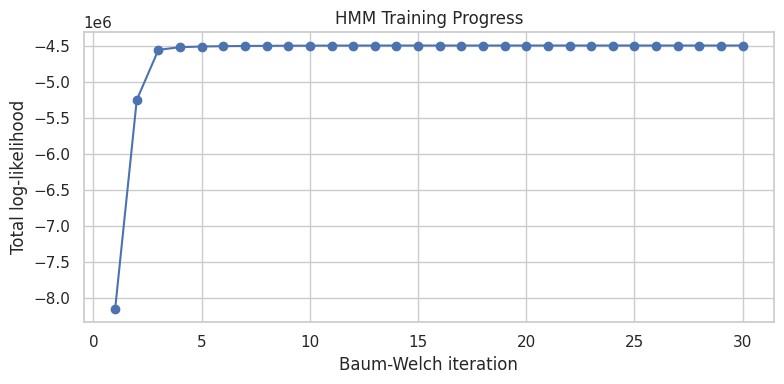


Initial state probabilities:
[0.25 0.   0.4  0.35]

Transition matrix (rows = current state, columns = next state):


,State 0,State 1,State 2,State 3
State 0,0.990,0.003,0.005,0.002
State 1,0.003,0.984,0.000,0.013
State 2,0.003,0.000,0.996,0.000
State 3,0.004,0.018,0.001,0.977



State means in standardized feature space:


,Heart_Rate,BP_Systolic,BP_Diastolic,SpO2,Respiration_Rate,Body_Temperature
State 0,0.87,1.45,1.46,-1.02,1.13,0.50
State 1,0.37,0.18,0.13,-0.00,0.40,-0.49
State 2,-0.60,-0.98,-0.94,0.64,-0.77,-0.37
State 3,-0.40,-0.12,-0.17,0.04,-0.42,0.82


In [7]:
N_STATES = 4
hmm = GaussianHMM(n_states=N_STATES, n_iter=30, tol=1e-2, random_state=42)
hmm.fit(sequences)

plt.figure(figsize=(8, 4))
plt.plot(range(1, len(hmm.log_likelihood_history) + 1), hmm.log_likelihood_history, marker="o")
plt.xlabel("Baum-Welch iteration")
plt.ylabel("Total log-likelihood")
plt.title("HMM Training Progress")
plt.tight_layout()
plt.show()

print("\nInitial state probabilities:")
print(np.round(hmm.pi, 3))
print("\nTransition matrix (rows = current state, columns = next state):")
display(pd.DataFrame(
    hmm.A,
    index=[f"State {i}" for i in range(N_STATES)],
    columns=[f"State {i}" for i in range(N_STATES)]
).round(3))

print("\nState means in standardized feature space:")
display(pd.DataFrame(hmm.means, columns=feature_columns,
                     index=[f"State {i}" for i in range(N_STATES)]).round(2))

## Step 7: Interpret states as Stable, Sub-clinical, Acute, Critical
HMM state numbers are arbitrary. This cell creates a simple severity score from standardized vital signs. It treats higher heart rate, higher respiratory rate, lower SpO₂, and unusually high/low blood pressure as potentially more severe. It then orders the learned states by the score.

This is only an educational heuristic. If the dataset uses different features or has no oxygen saturation, the score will use whichever recognized features are available.

In [8]:
# A simple heuristic severity score on the standardized means.
feature_lower = [str(c).lower() for c in feature_columns]
severity = np.zeros(N_STATES)

for j, name in enumerate(feature_lower):
    vals = hmm.means[:, j]
    if any(x in name for x in ["spo2", "oxygen_saturation", "blood_oxygen"]):
        severity += -vals
    elif any(x in name for x in ["heart_rate", "heartrate", "pulse"]):
        severity += vals
    elif "respiratory" in name or "respiration" in name:
        severity += vals
    elif "systolic" in name or "diastolic" in name or name in ["sbp", "dbp"]:
        severity += np.abs(vals)

state_order = np.argsort(severity)
state_names = {
    int(state_order[0]): "Stable",
    int(state_order[1]): "Sub-clinical",
    int(state_order[2]): "Acute",
    int(state_order[3]): "Critical"
}
print("Heuristic state mapping (learned state -> illustrative label):")
print(state_names)
print("Severity scores by learned state:", np.round(severity, 3))

Heuristic state mapping (learned state -> illustrative label):
{3: 'Stable', 2: 'Sub-clinical', 1: 'Acute', 0: 'Critical'}
Severity scores by learned state: [ 5.921  1.082 -0.096 -0.566]


## Step 8: Decode patient states and visualize one sequence

Example patient: 1
Number of observations: 52560


,Timestamp,Heart_Rate,BP_Systolic,BP_Diastolic,SpO2,Respiration_Rate,Body_Temperature,hidden_state,interpreted_state
0,2025-01-01 00:00:00,64.983253,119.316229,74.359810,96.255476,13.306922,98.873764,3,Stable
1,2025-01-01 00:10:00,67.370818,120.036205,74.738841,96.251179,13.503687,98.900441,3,Stable
2,2025-01-01 00:20:00,65.942703,121.965136,75.406949,96.284318,13.747104,98.892635,3,Stable
3,2025-01-01 00:30:00,65.742632,122.971756,75.722588,96.539722,13.996816,98.903550,3,Stable
4,2025-01-01 00:40:00,66.055647,122.800885,75.843408,96.311951,13.968091,98.935292,3,Stable
5,2025-01-01 00:50:00,66.542643,122.373404,76.066659,96.390513,13.938080,98.939743,3,Stable
6,2025-01-01 01:00:00,66.151005,122.237144,77.099095,96.463581,14.335444,98.954644,3,Stable
7,2025-01-01 01:10:00,67.080112,122.775256,77.181155,96.512249,14.531875,98.898566,3,Stable
8,2025-01-01 01:20:00,66.916248,123.692980,77.581665,96.601062,14.835164,98.893544,3,Stable
9,2025-01-01 01:30:00,65.858149,123.060243,76.528142,96.723976,15.220953,98.881626,3,Stable


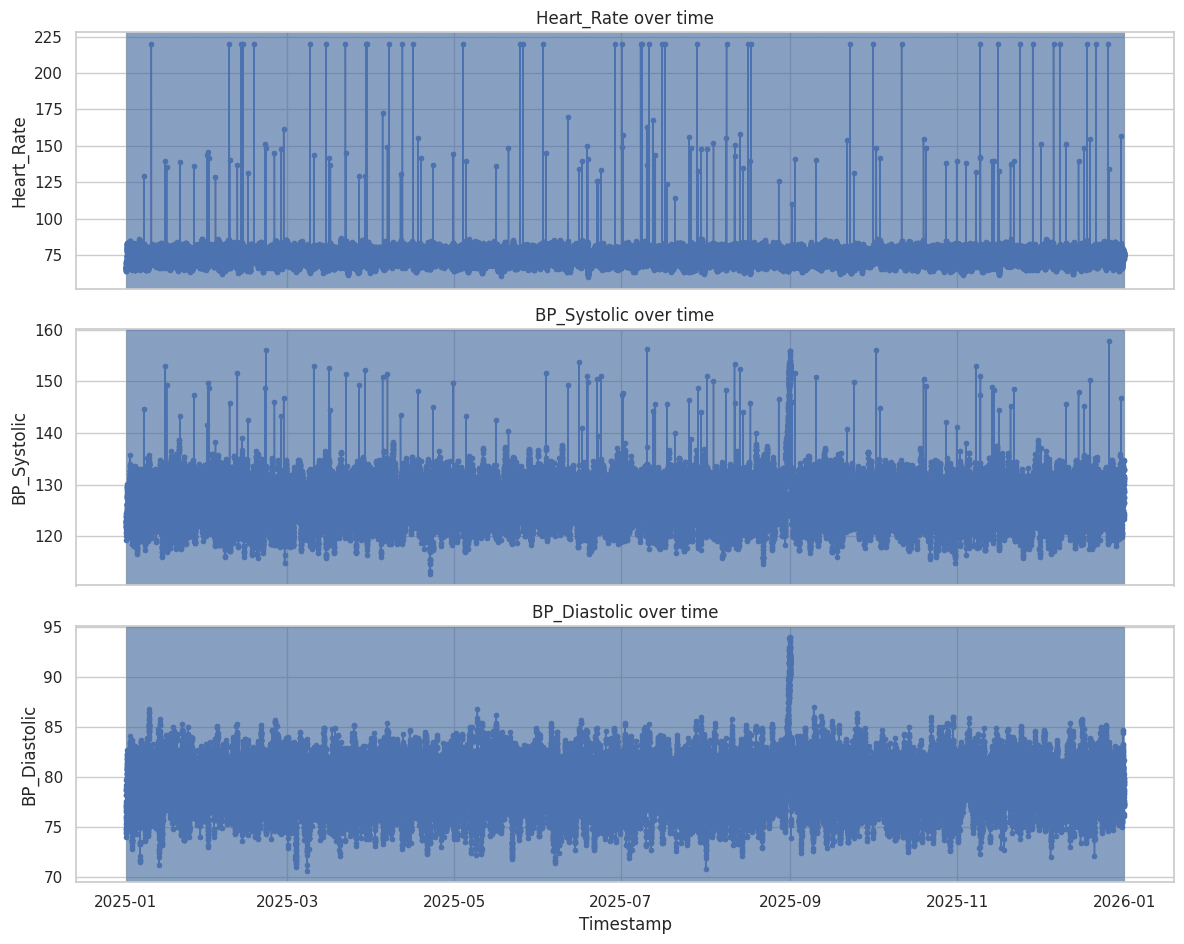

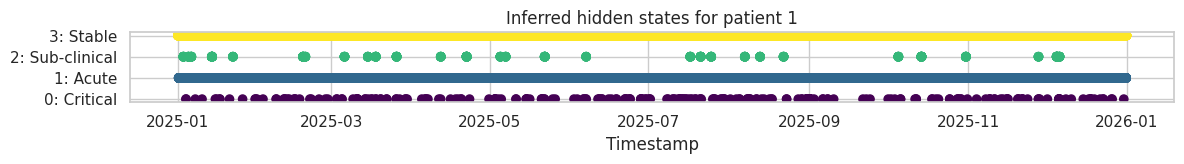

In [9]:
# Decode each patient sequence with Viterbi.
decoded_sequences = [hmm.predict(seq) for seq in sequences]

# Pick the patient with the longest sequence for a readable plot.
chosen_idx = int(np.argmax([len(seq) for seq in sequences]))
chosen_pid = sequence_patient_ids[chosen_idx]
chosen_data = data[data[patient_col] == chosen_pid].sort_values(time_col).copy()
chosen_states = decoded_sequences[chosen_idx]
chosen_data = chosen_data.iloc[:len(chosen_states)].copy()
chosen_data["hidden_state"] = chosen_states
chosen_data["interpreted_state"] = chosen_data["hidden_state"].map(state_names)

print("Example patient:", chosen_pid)
print("Number of observations:", len(chosen_data))
display(chosen_data[[time_col] + feature_columns + ["hidden_state", "interpreted_state"]].head(10))

# Plot available vital signs over time.
plot_features = feature_columns[:min(3, len(feature_columns))]
fig, axes = plt.subplots(len(plot_features), 1, figsize=(12, 3.2 * len(plot_features)), sharex=True)
if len(plot_features) == 1:
    axes = [axes]

for ax, col in zip(axes, plot_features):
    ax.plot(chosen_data[time_col], chosen_data[col], marker=".", linewidth=1)
    ax.set_ylabel(col)
    ax.set_title(f"{col} over time")
    # Mark state changes along the timeline.
    for _, row in chosen_data.iterrows():
        ax.axvline(row[time_col], alpha=0.025, linewidth=0.5)

axes[-1].set_xlabel("Timestamp")
plt.tight_layout()
plt.show()

plt.figure(figsize=(12, 1.8))
plt.scatter(chosen_data[time_col], chosen_data["hidden_state"], c=chosen_data["hidden_state"], cmap="viridis", s=35)
plt.yticks(range(N_STATES), [f"{i}: {state_names[i]}" for i in range(N_STATES)])
plt.xlabel("Timestamp")
plt.title(f"Inferred hidden states for patient {chosen_pid}")
plt.tight_layout()
plt.show()

## Step 9: Plot the transition matrix and summarize results

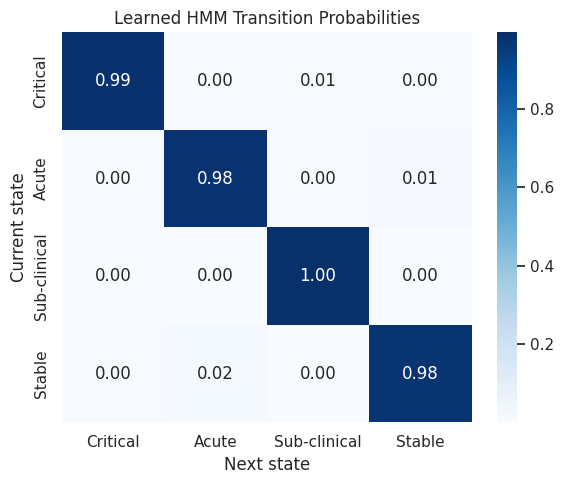

,Item,Result
0,Patients/sequences used,20
1,Total observations,1051200
2,Vital-sign features,"Heart_Rate, BP_Systolic, BP_Diastolic, SpO2, R..."
3,Hidden states,4
4,Baum-Welch iterations completed,30
5,Final total log-likelihood,-4497420.92


Interpretation notes:
- Forward-Backward uses scaling factors to reduce numerical underflow.
- Baum-Welch estimates HMM parameters by iteratively improving sequence likelihood.
- Viterbi returns the most likely hidden-state path for each patient sequence.
- The state labels are heuristic interpretations, not ground-truth clinical labels.

Part B notebook complete.


In [10]:
plt.figure(figsize=(6, 5))
sns.heatmap(
    hmm.A, annot=True, fmt=".2f", cmap="Blues",
    xticklabels=[state_names[i] for i in range(N_STATES)],
    yticklabels=[state_names[i] for i in range(N_STATES)]
)
plt.xlabel("Next state")
plt.ylabel("Current state")
plt.title("Learned HMM Transition Probabilities")
plt.tight_layout()
plt.show()

summary = pd.DataFrame({
    "Item": [
        "Patients/sequences used",
        "Total observations",
        "Vital-sign features",
        "Hidden states",
        "Baum-Welch iterations completed",
        "Final total log-likelihood"
    ],
    "Result": [
        len(sequences),
        sum(len(s) for s in sequences),
        ", ".join(map(str, feature_columns)),
        N_STATES,
        len(hmm.log_likelihood_history),
        round(hmm.log_likelihood_history[-1], 2)
    ]
})
display(summary)

print("Interpretation notes:")
print("- Forward-Backward uses scaling factors to reduce numerical underflow.")
print("- Baum-Welch estimates HMM parameters by iteratively improving sequence likelihood.")
print("- Viterbi returns the most likely hidden-state path for each patient sequence.")
print("- The state labels are heuristic interpretations, not ground-truth clinical labels.")
print("\nPart B notebook complete.")